# HDB Rentals: interpreting the GNN (prototype)

What the block GNN bases its rent predictions on, and whether those explanations can be trusted.

| | |
|---|---|
| **Model** | `hdb_rentals.gnn`, `GNN_uniform` (seeds 0, 1, 2) and the graph-free control `MLP_matched` (seed 0), damped market level, the GNN's own block table |
| **Data** | fit 2021-01 to 2023-12, explain and score 2024-01 to 2025-03 (the windows of `scripts/compare_gnn_nb10.py`). Epoch counts are the ones that script chose on its tuning split |
| **Explained** | 400 random holdout rentals |
| **Method** | Integrated Gradients (32 steps) from an *average flat in an average block* to the actual inputs, on each rental's exact 2-hop subgraph |
| **Reference** | LightGBM on the same inputs and target, explained with TreeSHAP |
| **Not used** | anything from notebook 10's appendices |

Questions, one section each:

1. Where does one flat's predicted rent come from, in dollars?
2. Which features matter across flats, and does LightGBM agree?
3. Does the GNN use its neighbours?
4. Can these explanations be trusted?
5. Does the explainer find a neighbour effect we planted ourselves?
6. What does a GNN that learns its own edge weights learn, and do its weights agree with IG?

The explainer lives in `hdb_rentals.explain` (tests in `tests/test_explain.py`).

**Why not attribute to edges directly.** The GNN normalises edge weights per receiving block, so scaling all
of a block's edges by the same factor changes nothing: Integrated Gradients on an edge mask sums to zero by
construction. Neighbour influence is measured instead through the neighbouring blocks' *features* (IG) and by
deleting edges (`edge_mask=0`).

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]

import torch  # before LightGBM, as the GNN scripts note
import experiment_weighted_gnns as ewg
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from hdb_rentals import gnn
from hdb_rentals.explain import SubgraphExplainer

torch.set_num_threads(4)
OUT = ROOT / "outputs" / "11_interpretability"
(OUT / "models").mkdir(parents=True, exist_ok=True)
RETRAIN = False          # True retrains the GNNs instead of loading outputs/11_interpretability/models
N_ROWS, IG_STEPS = 400, 32
SEEDS = [0, 1, 2]
HOLD_START, HOLD_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-04-01")

BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e2e1dc", "#fcfcfb", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110, "axes.axisbelow": True,
})

## Data, features and models

`ewg.prepare` builds the GNN's inputs. The two preprocessors are re-fitted here only to name its columns;
the assert checks they produce the same matrices.

In [2]:
rent, blocks, graph = ewg.rent, ewg.blocks, ewg.GRAPH
fit = rent[rent.RENT_APPROVAL_DATE < HOLD_START].copy()
hold = rent[(rent.RENT_APPROVAL_DATE >= HOLD_START) & (rent.RENT_APPROVAL_DATE < HOLD_END)].copy()
bundle = ewg.prepare(fit, hold)
part = bundle["parts"][1]

BLOCK_NUM, BLOCK_CAT = ewg.BLOCK_NUM, ewg.BLOCK_CAT + ["SUBZONE"]
REC_NUM, REC_CAT = ["FLOOR_AREA_SQM", "FLAT_AGE"], ["FLAT_TYPE", "FLAT_MODEL"]
bp = ewg.preprocessor(BLOCK_NUM, BLOCK_CAT).fit(blocks.iloc[np.sort(fit.block_id.unique())])
rp = ewg.preprocessor(REC_NUM, REC_CAT).fit(fit)
assert np.allclose(bp.transform(blocks), bundle["nodes"].numpy())
assert np.allclose(rp.transform(hold), part["record"].numpy())


def source_column(name, cat):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest.removeprefix("missingindicator_")
    return next(c for c in cat if rest.startswith(c + "_"))


def family(col):
    named = {"FLOOR_AREA_SQM": "Floor area", "FLAT_AGE": "Flat age", "FLAT_TYPE": "Flat type",
             "FLAT_MODEL": "Flat model", "LATITUDE": "Coordinates", "LONGITUDE": "Coordinates",
             "MAX_FLOOR": "Building height, year", "YEAR_COMPLETED": "Building height, year",
             "TOWN": "Town, area", "PLANNING_AREA": "Town, area", "SUBZONE": "Town, area"}
    if col in named:
        return named[col]
    for prefix, name in [("mrt_", "MRT access"), ("mall_", "Malls"),
                         (("school_", "primary_", "secondary_"), "Schools")]:
        if col.startswith(prefix):
            return name
    raise KeyError(col)


NODE_COLS = [source_column(n, BLOCK_CAT) for n in bp.get_feature_names_out()]
REC_COLS = [source_column(n, REC_CAT) for n in rp.get_feature_names_out()]
NODE_FAM = np.array([family(c) for c in NODE_COLS])
REC_FAM = np.array([family(c) for c in REC_COLS])
FLAT_FAMS = ["Floor area", "Flat type", "Flat model", "Flat age"]
LOC_FAMS = ["Town, area", "Coordinates", "MRT access", "Schools", "Malls", "Building height, year"]
print(f"{len(fit):,} fit rows, {len(hold):,} holdout rows; {len(REC_COLS)} record and {len(NODE_COLS)} block "
      f"input columns; {graph.n_nodes:,} blocks, {graph.n_edges:,} directed edges")

105,837 fit rows, 44,163 holdout rows; 27 record and 254 block input columns; 9,464 blocks, 87,932 directed edges


In [3]:
epochs = (pd.read_csv(ROOT / "outputs/gnn_vs_nb10/results.csv")
          .query("split == 'holdout' and level == 'damped' and features == 'gnn'")
          .set_index("model").epochs.astype(int))


def get_model(kind, seed):
    path = OUT / "models" / f"{kind}_seed{seed}.pt"
    if path.exists() and not RETRAIN:
        return gnn.load_model(path, graph)[0]
    n_epochs = int(epochs.get(kind, epochs["GNN_uniform"]))  # GNN_learned_edges: GNN_uniform's count
    model, _, _ = ewg.train(kind, bundle, seed, n_epochs, save_to=path, window="2021-01..2023-12")
    return model.eval()


models = {f"GNN seed {s}": get_model("GNN_uniform", s) for s in SEEDS}
models["MLP (graph off)"] = get_model("MLP_matched", 0)
gnn.seed_everything(99)  # an untrained GNN, for the randomisation check in section 4
models["GNN untrained"] = gnn.WeightedRentalGNN("GNN_uniform", bundle["nodes"].shape[1],
                                                part["record"].shape[1], graph).eval()


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))


reported = pd.read_csv(ROOT / "outputs/gnn_vs_nb10/summary.csv").query("level == 'damped' and features == 'gnn'")
print("holdout RMSE (compare_gnn_nb10 reported GNN_uniform "
      f"{reported.set_index('model').holdout['GNN_uniform']}, MLP_matched {reported.set_index('model').holdout['MLP_matched']})")
for name, m in models.items():
    print(f"  {name:16s} {rmse(gnn.predict(m, bundle, part), part['y']):7.1f}")

holdout RMSE (compare_gnn_nb10 reported GNN_uniform 489.81, MLP_matched 488.81)
  GNN seed 0         489.8
  GNN seed 1         489.6
  GNN seed 2         489.4
  MLP (graph off)    488.8
  GNN untrained      676.4


### The explainer

For rental *i* in block *b*, the prediction depends only on blocks within two hops of *b* (two message-passing
layers). `SubgraphExplainer` cuts the trained model down to that neighbourhood and runs IG there, with the
steps batched as disjoint copies; section 4 checks the cut model against the full graph.

The baseline is the mean record of the fit rows in every block set to the mean block: with all blocks equal,
the graph has nothing to pass on. IG's attributions then sum to *f(x) − f(baseline)* (completeness). Model
output is a standardised premium: dollars = output × std × the month's market multiplier.

In [4]:
explainer = SubgraphExplainer(graph.edge_index, graph.n_nodes)
coords = blocks[["LATITUDE", "LONGITUDE"]].to_numpy()
FIT_BLOCKS = np.sort(fit.block_id.unique())
NODE_BASE = bundle["nodes"][FIT_BLOCKS].mean(0)
REC_BASE = bundle["parts"][0]["record"].mean(0)
NODES = bundle["nodes"]


@torch.no_grad()
def full_outputs(model, edge_mask=None):
    return model(NODES, part, edge_mask).numpy()


def explain(model, rows, steps=IG_STEPS):
    # Per row: record, own-block and neighbour attributions, and the subgraph vs full-graph output.
    f_full = full_outputs(model)
    out = []
    for i in rows:
        e = explainer.explain(model, NODES, part["record"][i], int(part["ids"][i]), row=i,
                              node_base=NODE_BASE, record_base=REC_BASE, steps=steps)
        out.append(dict(row=i, block=e.block, S=e.nodes, lb=e.local, rec=e.record, own=e.own, nbr=e.neighbours,
                        nbr_blocks=e.neighbour_blocks, f_full=float(f_full[i]), f_sub=e.output, base=e.baseline))
    return out


rows = np.sort(np.random.default_rng(0).choice(len(hold), N_ROWS, replace=False))
dollars = bundle["std"] * part["scale"]          # model units -> SGD, per holdout row
explanations, base_out = {}, {}
for name, m in models.items():
    explanations[name] = explain(m, rows)
    base_out[name] = explanations[name][0]["base"]
print("explained", len(rows), "rows for", len(models), "models")

explained 400 rows for 5 models


## 1. Where does one flat's rent come from?

Predicted rent = (average flat × the month's market level) + what makes this flat, its block and its
neighbours differ from average. The first bar is the average flat at the January 2021 market (the market
multiplier is 1 there); the second is how far the damped market level has moved it by the rental's month.

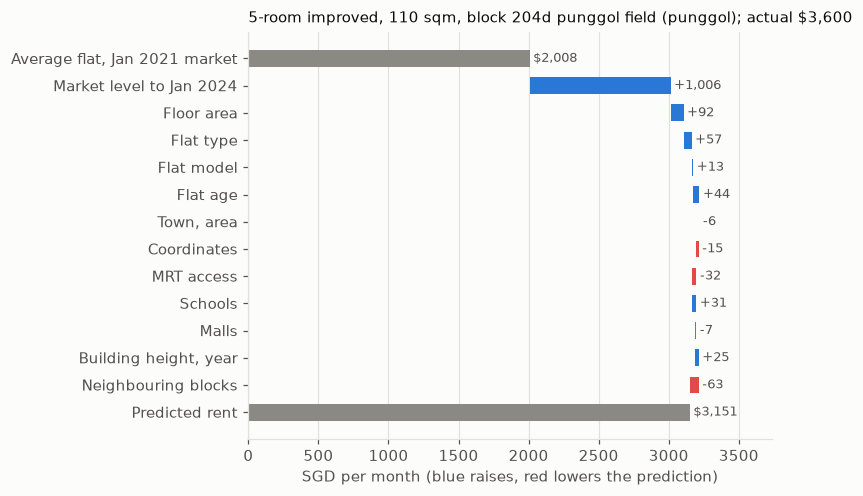

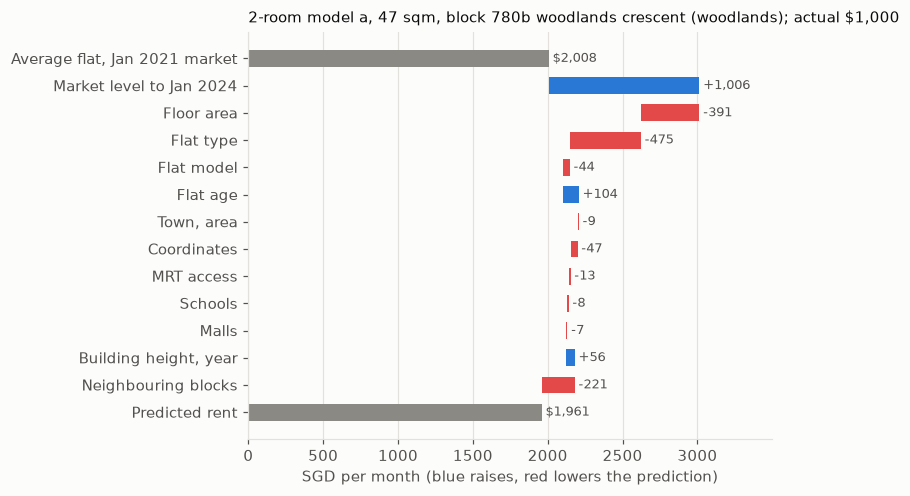

In [5]:
def family_dollars(e, name):
    i = e["row"]
    d = dollars[i]
    flat = pd.Series(e["rec"] * d).groupby(REC_FAM).sum()
    own = pd.Series(e["own"] * d).groupby(NODE_FAM).sum()
    return pd.concat([flat, own]), float(e["nbr"].sum() * d)


def waterfall(name, k):
    e = explanations[name][k]
    i = e["row"]
    scale = part["scale"][i]
    avg = (base_out[name] * bundle["std"] + bundle["mean"])
    fam, nbr = family_dollars(e, name)
    fam = fam.reindex(FLAT_FAMS + LOC_FAMS).fillna(0)
    steps = [("Average flat, Jan 2021 market", avg, "total"),
             (f"Market level to {hold.RENT_APPROVAL_DATE.iloc[i]:%b %Y}", avg * (scale - 1), "delta")]
    steps += [(f, v, "delta") for f, v in fam.items()]
    steps += [("Neighbouring blocks", nbr, "delta")]
    pred = (e["f_full"] * bundle["std"] + bundle["mean"]) * scale
    steps += [("Predicted rent", pred, "total")]
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    run, peak = 0.0, 0.0
    for y, (label, v, kind) in enumerate(steps):
        if kind == "total":
            left, width, color = 0, v, NEUTRAL
            run = v
        else:
            left, width, color = min(run, run + v), abs(v), BLUE if v >= 0 else RED
            run += v
        peak = max(peak, left + width)
        ax.barh(y, width, left=left, height=0.62, color=color)
        text = f"${v:,.0f}" if kind == "total" else f"{v:+,.0f}"
        ax.text(left + width + 25, y, text, va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(range(len(steps)), [s[0] for s in steps])
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, peak * 1.16)
    flat = hold.iloc[i]
    ax.set_title(f"{flat.FLAT_TYPE} {flat.FLAT_MODEL}, {flat.FLOOR_AREA_SQM:.0f} sqm, block {flat.BLOCK} "
                 f"{flat.STREET} ({flat.TOWN}); actual ${flat.MONTHLY_RENT:,.0f}", fontsize=9.5)
    ax.set_xlabel("SGD per month (blue raises, red lowers the prediction)")
    fig.tight_layout()
    return fig


for k in [0, 1]:
    waterfall("GNN seed 0", k).savefig(OUT / f"waterfall_{k}.png", bbox_inches="tight")
    plt.show()

## 2. Which features matter across flats, and does LightGBM agree?

Mean absolute contribution in dollars over the 400 rentals, by feature family. LightGBM is fitted to the same
target (rent ÷ market multiplier) on the same columns (block table joined to each rental) and explained with
TreeSHAP, also in dollars. LightGBM has no neighbours, so the GNN's neighbour bar has no counterpart.

LightGBM (same target and columns) holdout RMSE 484.3


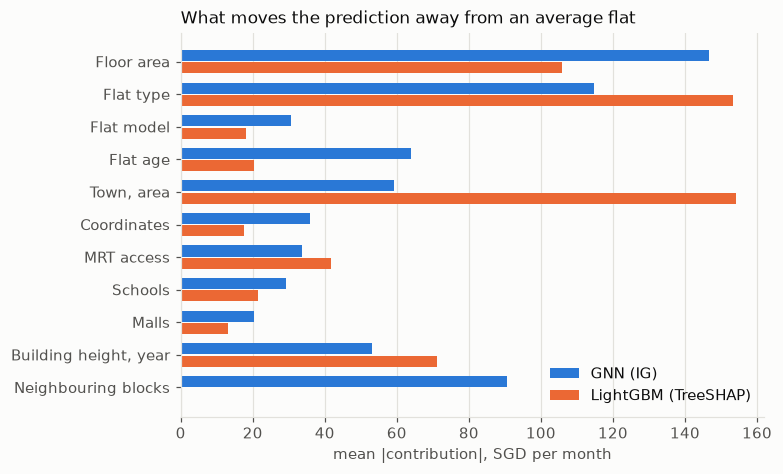

rank agreement between GNN and LightGBM over 10 shared families: Spearman 0.68


,GNN (IG),LightGBM (TreeSHAP)
Floor area,146.7,105.8
Flat type,114.8,153.3
Flat model,30.5,18.0
Flat age,64.0,20.2
"Town, area",59.2,154.3
Coordinates,36.0,17.7
MRT access,33.6,41.8
Schools,29.4,21.4
Malls,20.4,13.2
"Building height, year",53.1,71.1


In [6]:
def global_families(name):
    tab = pd.DataFrame([family_dollars(e, name)[0] for e in explanations[name]]).fillna(0)
    tab["Neighbouring blocks"] = [family_dollars(e, name)[1] for e in explanations[name]]
    return tab


LGBM_PARAMS = dict(num_leaves=63, min_child_samples=100, subsample=0.85, subsample_freq=1, colsample_bytree=0.5,
                   reg_lambda=20.0, cat_smooth=30.0, n_estimators=357, learning_rate=0.05, verbose=-1, random_state=0)


def tabular(frame):
    X = frame[REC_NUM + REC_CAT].reset_index(drop=True).join(
        blocks.loc[frame.block_id.to_numpy(), BLOCK_NUM + BLOCK_CAT].reset_index(drop=True))
    for c in REC_CAT + BLOCK_CAT:
        X[c] = pd.Categorical(X[c], categories=sorted(rent[c].dropna().unique()) if c in rent else
                              sorted(blocks[c].dropna().unique()))
    return X


fit_scale = bundle["parts"][0]["scale"]
lgbm = lgb.LGBMRegressor(**LGBM_PARAMS).fit(tabular(fit), fit.MONTHLY_RENT.to_numpy() / fit_scale)
X_hold = tabular(hold)
print(f"LightGBM (same target and columns) holdout RMSE {rmse(lgbm.predict(X_hold) * part['scale'], part['y']):.1f}")
contrib = lgbm.predict(X_hold.iloc[rows], pred_contrib=True)[:, :-1] * part["scale"][rows, None]
shap_fam = pd.DataFrame(contrib, columns=X_hold.columns).T.groupby(lambda c: family(c)).sum().T

order = FLAT_FAMS + LOC_FAMS + ["Neighbouring blocks"]
importance = pd.DataFrame({
    "GNN (IG)": global_families("GNN seed 0").abs().mean().reindex(order),
    "LightGBM (TreeSHAP)": shap_fam.abs().mean().reindex(order),
})
fig, ax = plt.subplots(figsize=(7.2, 4.4))
y = np.arange(len(order))
for j, (col, color) in enumerate(zip(importance.columns, [BLUE, ORANGE])):
    ax.barh(y + (j - 0.5) * 0.38, importance[col].fillna(0), height=0.34, color=color, label=col)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |contribution|, SGD per month")
ax.set_title("What moves the prediction away from an average flat")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "importance_gnn_vs_lgbm.png", bbox_inches="tight")
plt.show()

both = importance.dropna()
rho = spearmanr(both.iloc[:, 0], both.iloc[:, 1]).statistic
print(f"rank agreement between GNN and LightGBM over {len(both)} shared families: Spearman {rho:.2f}")
importance.round(1)

## 3. Does the GNN use its neighbours?

Three measurements on the same rentals:

- **share of attribution on neighbouring blocks** (IG, out of all |attribution|);
- **deleting every edge** (`edge_mask = 0`): how far each prediction moves;
- the **holdout RMSE** of the GNN against the identical network with the graph switched off.

The graph-free MLP must show zero on the first two; it is the check that the measurements are wired right.

In [7]:
reliance = []
for name in ["GNN seed 0", "GNN seed 1", "GNN seed 2", "MLP (graph off)"]:
    m, ex = models[name], explanations[name]
    nbr = np.array([np.abs(e["nbr"]).sum() * dollars[e["row"]] for e in ex])
    tot = np.array([(np.abs(e["rec"]).sum() + np.abs(e["own"]).sum() + np.abs(e["nbr"]).sum()) * dollars[e["row"]]
                    for e in ex])
    moved = np.abs(full_outputs(m) - full_outputs(m, torch.zeros(graph.n_edges))) * dollars
    reliance.append({"model": name, "holdout RMSE": rmse(gnn.predict(m, bundle, part), part["y"]),
                     "neighbour share of |IG|": nbr.sum() / tot.sum(),
                     "mean |Δ$| with all edges removed": moved.mean(),
                     "95th pct |Δ$|": np.percentile(moved, 95)})
reliance = pd.DataFrame(reliance).set_index("model")
reliance.style.format({"holdout RMSE": "{:.1f}", "neighbour share of |IG|": "{:.1%}",
                       "mean |Δ$| with all edges removed": "{:.1f}", "95th pct |Δ$|": "{:.1f}"})

,holdout RMSE,neighbour share of |IG|,mean |Δ$| with all edges removed,95th pct |Δ$|
model,,,,
GNN seed 0,489.8,27.1%,91.9,224.1
GNN seed 1,489.6,26.0%,114.3,266.3
GNN seed 2,489.4,30.1%,99.1,236.6
MLP (graph off),488.8,0.0%,0.0,0.0


The GNN gives neighbours a real share of the credit, yet predicts no better than the graph-free MLP. One
reading: neighbouring blocks carry much the same location information as the rental's own block, so the GNN
spreads location credit over both while the MLP puts it all on the own block. If so, the GNN's *net* location
effect (own block + neighbours) should match the MLP's own-block location effect, rental by rental.

Deleting every edge is also not a fair test of *need*: the GNN never saw a block without messages in
training, so that input is out of distribution and the dollar shift is an upper bound.

In [8]:
def location_effects(name):
    g = global_families(name)
    return pd.DataFrame({"flat": g.reindex(columns=FLAT_FAMS).sum(1),
                         "own block": g.reindex(columns=LOC_FAMS).sum(1),
                         "neighbours": g["Neighbouring blocks"]})


g0, mlp = location_effects("GNN seed 0"), location_effects("MLP (graph off)")
gnn_location = g0["own block"] + g0["neighbours"]
substitution = pd.DataFrame({
    "mean |net effect| $": [g0["flat"].abs().mean(), g0["own block"].abs().mean(), g0["neighbours"].abs().mean(),
                            gnn_location.abs().mean(), mlp["flat"].abs().mean(), mlp["own block"].abs().mean()],
}, index=["GNN: flat", "GNN: own block", "GNN: neighbours", "GNN: own block + neighbours",
          "MLP: flat", "MLP: own block"])
print(f"per-rental correlation, GNN own+neighbours vs MLP own-block location effect: "
      f"{np.corrcoef(gnn_location, mlp['own block'])[0, 1]:.2f}  "
      f"(GNN own block alone vs MLP own block: {np.corrcoef(g0['own block'], mlp['own block'])[0, 1]:.2f})")
substitution.round(1)

C:\Users\ky\AppData\Local\Temp\ipykernel_2844\2826361037.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  return pd.DataFrame({"flat": g.reindex(columns=FLAT_FAMS).sum(1),
C:\Users\ky\AppData\Local\Temp\ipykernel_2844\2826361037.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "own block": g.reindex(columns=LOC_FAMS).sum(1),


per-rental correlation, GNN own+neighbours vs MLP own-block location effect: 0.98  (GNN own block alone vs MLP own block: 0.98)


C:\Users\ky\AppData\Local\Temp\ipykernel_2844\2826361037.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  return pd.DataFrame({"flat": g.reindex(columns=FLAT_FAMS).sum(1),
C:\Users\ky\AppData\Local\Temp\ipykernel_2844\2826361037.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "own block": g.reindex(columns=LOC_FAMS).sum(1),


,mean |net effect| $
GNN: flat,271.7
GNN: own block,116.7
GNN: neighbours,90.6
GNN: own block + neighbours,197.5
MLP: flat,255.2
MLP: own block,202.6


How far does neighbour influence reach? Each neighbour's total attribution, against its distance from the
rental's block, split by hop (1 hop = a direct edge, edges are at most 1 km long).

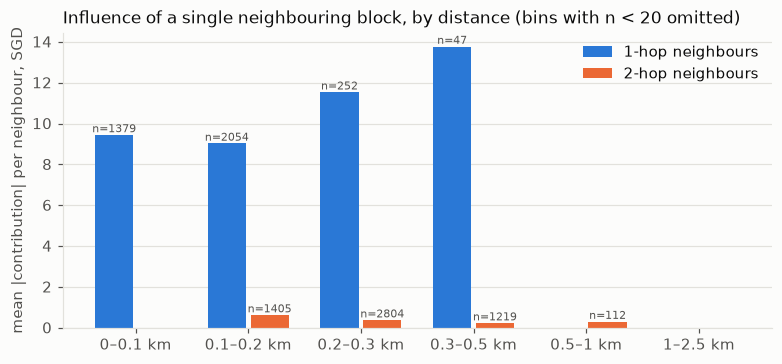

neighbours by hop: {1: {'size': 3733, 'mean': 9.41}, 2: {'size': 5546, 'mean': 0.41}}
1-hop: Spearman of |contribution| with distance 0.03


In [9]:
def haversine_km(a, b):
    p = np.radians(np.r_[a, b].reshape(2, 2))
    dlat, dlon = p[1] - p[0]
    h = np.sin(dlat / 2) ** 2 + np.cos(p[0, 0]) * np.cos(p[1, 0]) * np.sin(dlon / 2) ** 2
    return 2 * gnn.EARTH_KM * np.arcsin(np.sqrt(h))


records = []
for e in explanations["GNN seed 0"]:
    one = set(explainer.adjacency[e["block"]].indices)
    for nb, attr in zip(e["nbr_blocks"], e["nbr"].sum(1)):
        records.append(dict(km=haversine_km(coords[e["block"]], coords[nb]), hop=1 if nb in one else 2,
                            dollars=abs(attr) * dollars[e["row"]]))
reach = pd.DataFrame(records)
reach["band"] = pd.cut(reach.km, [0, 0.1, 0.2, 0.3, 0.5, 1.0, 2.5], right=False)
by_band = reach.pivot_table(index="band", columns="hop", values="dollars", aggfunc="mean", observed=False)
counts = reach.pivot_table(index="band", columns="hop", values="dollars", aggfunc="size", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(by_band))
for j, (hop, color) in enumerate(zip([1, 2], [BLUE, ORANGE])):
    vals = by_band[hop].where(counts[hop] >= 20)   # bins with fewer than 20 neighbours are not drawn
    ax.bar(x + (j - 0.5) * 0.38, vals.fillna(0), width=0.34, color=color, label=f"{hop}-hop neighbours")
    for xi, v, n in zip(x, vals, counts[hop]):
        if n >= 20:
            ax.text(xi + (j - 0.5) * 0.38, v, f"n={int(n)}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(x, [f"{b.left:g}–{b.right:g} km" for b in by_band.index])
ax.grid(axis="x", visible=False)
ax.set_ylabel("mean |contribution| per neighbour, SGD")
ax.set_title("Influence of a single neighbouring block, by distance (bins with n < 20 omitted)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "neighbour_reach.png", bbox_inches="tight")
plt.show()
print("neighbours by hop:", reach.groupby("hop").dollars.agg(["size", "mean"]).round(2).to_dict("index"))
print("1-hop: Spearman of |contribution| with distance", round(spearmanr(reach.query("hop == 1").km,
                                                                         reach.query("hop == 1").dollars).statistic, 2))

## 4. Can these explanations be trusted?

- **Exactness**: subgraph prediction = full-graph prediction; IG completeness error.
- **Fidelity**: setting the *k* most-attributed inputs to their baseline must move the prediction more than
  setting *k* random inputs. Two random pools: every input in the 2-hop subgraph (thousands, most of them
  neighbour columns that barely matter, so an easy bar), and only the rental's own record and block columns
  (a harder bar).
- **Seed stability**: the per-rental ranking of feature families should agree across the three trained seeds.
- **Randomisation**: an untrained GNN must give *different* explanations; if it agreed with the trained one,
  the explanations would reflect the inputs, not what the model learned.

In [10]:
checks = []
for name, ex in explanations.items():
    sub_err = max(abs(e["f_sub"] - e["f_full"]) for e in ex)
    comp = [abs(e["rec"].sum() + e["own"].sum() + e["nbr"].sum() - (e["f_full"] - base_out[name])) * dollars[e["row"]]
            for e in ex]
    checks.append({"model": name, "max |subgraph − full| (model units)": sub_err,
                   "median completeness error $": np.median(comp), "max completeness error $": np.max(comp)})
pd.DataFrame(checks).set_index("model").style.format("{:.2g}")

,max |subgraph − full| (model units),median completeness error $,max completeness error $
model,,,
GNN seed 0,2.4e-07,1.1,18
GNN seed 1,2.4e-07,1.2,14
GNN seed 2,2.4e-07,1.1,16
MLP (graph off),1.2e-07,1.7,43
GNN untrained,3e-08,0.16,0.92


In [11]:
@torch.no_grad()
def fidelity(name, ks=(1, 3, 5, 10, 20), draws=5, seed=0):
    rng = np.random.default_rng(seed)
    model = models[name]
    res = {k: ([], [], []) for k in ks}
    for e in explanations[name]:
        i, S, lb = e["row"], e["S"], e["lb"]
        sub = explainer.submodel(model, S)
        x, r = NODES[S].clone(), part["record"][i].clone()
        attr = np.r_[e["rec"], np.insert(e["nbr"], lb, e["own"], axis=0).ravel()]
        diff = np.r_[(r - REC_BASE).numpy(), (x - NODE_BASE).numpy().ravel()]
        pool = np.flatnonzero(np.abs(diff) > 1e-9)
        n_local = len(r) + (lb + 1) * x.shape[1]
        own_pool = pool[(pool < len(r)) | ((pool >= len(r) + lb * x.shape[1]) & (pool < n_local))]
        top = pool[np.argsort(-np.abs(attr[pool]))]
        base_flat = np.r_[REC_BASE.numpy(), NODE_BASE.expand_as(x).numpy().ravel()]
        full_flat = np.r_[r.numpy(), x.numpy().ravel()]

        def score(idx):
            v = full_flat.copy()
            v[idx] = base_flat[idx]
            rr = torch.tensor(v[:len(r)], dtype=torch.float32)
            xx = torch.tensor(v[len(r):].reshape(x.shape), dtype=torch.float32)
            return float(sub(xx, dict(ids=torch.tensor([lb]), record=rr[None]))[0])

        for k in ks:
            if k > len(pool):
                continue
            res[k][0].append(abs(score(top[:k]) - e["f_sub"]) * dollars[i])
            res[k][1].append(np.mean([abs(score(rng.choice(pool, k, replace=False)) - e["f_sub"]) * dollars[i]
                                      for _ in range(draws)]))
            if k <= len(own_pool):
                res[k][2].append(np.mean([abs(score(rng.choice(own_pool, k, replace=False)) - e["f_sub"]) * dollars[i]
                                          for _ in range(draws)]))
    return pd.DataFrame({k: {"top-k |Δ$|": np.mean(t), "random-k, whole subgraph": np.mean(rd),
                             "random-k, flat + own block": np.mean(ro)} for k, (t, rd, ro) in res.items()}).T


fid = fidelity("GNN seed 0")
fid["ratio vs flat + own block"] = fid["top-k |Δ$|"] / fid["random-k, flat + own block"]
fid.index.name = "k inputs reset"
fid.round(1)

,top-k |Δ$|,"random-k, whole subgraph","random-k, flat + own block",ratio vs flat + own block
k inputs reset,,,,
1,199.9,0.4,3.6,56.1
3,282.7,0.8,10.3,27.5
5,293.2,1.1,15.3,19.1
10,303.2,2.8,27.4,11.1
20,314.9,3.9,47.0,6.7


In [12]:
def family_matrix(name):
    return global_families(name).reindex(columns=FLAT_FAMS + LOC_FAMS + ["Neighbouring blocks"]).fillna(0).abs()


def mean_row_spearman(a, b):
    vals = [spearmanr(x, y).statistic for x, y in zip(family_matrix(a).to_numpy(), family_matrix(b).to_numpy())]
    return float(np.nanmean(vals))


pairs = [("GNN seed 0", "GNN seed 1"), ("GNN seed 0", "GNN seed 2"), ("GNN seed 1", "GNN seed 2"),
         ("GNN seed 0", "GNN untrained"), ("GNN seed 0", "MLP (graph off)")]
stability = pd.DataFrame([{"pair": f"{a} vs {b}", "mean per-rental Spearman (11 families)": mean_row_spearman(a, b)}
                          for a, b in pairs]).set_index("pair")
stability.round(2)

,mean per-rental Spearman (11 families)
pair,
GNN seed 0 vs GNN seed 1,0.79
GNN seed 0 vs GNN seed 2,0.78
GNN seed 1 vs GNN seed 2,0.77
GNN seed 0 vs GNN untrained,0.24
GNN seed 0 vs MLP (graph off),0.55


## 5. A planted neighbour effect: does the explainer find it?

The real data has no ground truth for "which neighbour mattered", so we make one. Every block gets a random
number *u* (standard normal, independent of location) as an extra block column, and the rent of a flat in
block *i* gets **+ β × (mean of *u* over *i*'s direct neighbours)**, at the month's market level. The flat's
own *u* is not used. Only a model that reads its neighbours can learn this, and we know each rental's true
dollar effect.

Three models, same epochs as above: the GNN on the planted rents, the graph-free MLP on the planted rents
(it cannot see neighbours, so it should be worse), and a control GNN that has the *u* column but real rents
(nothing to find, so the explainer should attribute about $0 to neighbours' *u*).

Two questions are separated below. *Did the model learn the effect?* Reset only the neighbours' *u* to the
baseline and read how far the prediction moves ("learned"), against the truth. *Does IG report what the model
learned?* IG on neighbours' *u* against that learned change; a slope near 1 means IG is faithful even where
the model learned only part of the truth.

In [13]:
import compare_gnn_nb10 as cmp

BETA = 150.0                                     # SGD at the January 2021 market; keeps every rent positive
u = np.random.default_rng(1).standard_normal(graph.n_nodes)
degree = np.asarray(explainer.adjacency.sum(1)).ravel()
neighbour_mean_u = np.divide(explainer.adjacency @ u, degree, out=np.zeros_like(u), where=degree > 0)  # 1 isolated block
blocks["PLANTED_U"] = u                          # ewg.blocks: prepare reads block columns from it
PLANTED_NUM = list(BLOCK_NUM) + ["PLANTED_U"]


def plant(frame, scale):
    out = frame.copy()
    out["MONTHLY_RENT"] = out.MONTHLY_RENT + BETA * neighbour_mean_u[out.block_id.to_numpy()] * scale
    assert (out.MONTHLY_RENT > 0).all()
    return out


fit_p, hold_p = plant(fit, bundle["parts"][0]["scale"]), plant(hold, part["scale"])
bundles5 = {"planted": cmp.prepare(fit_p, [hold_p], "damped", PLANTED_NUM),
            "control": cmp.prepare(fit, [hold], "damped", PLANTED_NUM)}
names5 = ewg.preprocessor(PLANTED_NUM, BLOCK_CAT).fit(blocks.iloc[FIT_BLOCKS]).get_feature_names_out()
U = list(names5).index("num__PLANTED_U")
assert np.allclose(bundles5["control"]["nodes"][:, U].numpy(), (u - u[FIT_BLOCKS].mean()) / u[FIT_BLOCKS].std(), atol=1e-4)


def get_planted(kind, which):
    path = OUT / "models" / f"planted_{which}_{kind}_seed0.pt"
    if path.exists() and not RETRAIN:
        return gnn.load_model(path, graph)[0]
    model, _, _ = ewg.train(kind, bundles5[which], 0, int(epochs[kind]), save_to=path, planted=which, beta=BETA)
    return model.eval()


specs5 = {"GNN, planted": ("GNN_uniform", "planted"), "MLP, planted": ("MLP_matched", "planted"),
          "GNN, control": ("GNN_uniform", "control")}
models5 = {name: (get_planted(*spec), bundles5[spec[1]]) for name, spec in specs5.items()}
effect = BETA * neighbour_mean_u[hold.block_id.to_numpy()] * part["scale"]
print(f"planted effect on holdout rents: sd ${effect.std():.0f}, mean |effect| ${np.abs(effect).mean():.0f}")
pd.DataFrame({name: {"holdout RMSE on its own target": rmse(gnn.predict(m, b, b["parts"][1]), b["parts"][1]["y"])}
              for name, (m, b) in models5.items()}).T.round(1)

planted effect on holdout rents: sd $75, mean |effect| $60


,holdout RMSE on its own target
"GNN, planted",489.3
"MLP, planted",490.8
"GNN, control",489.0


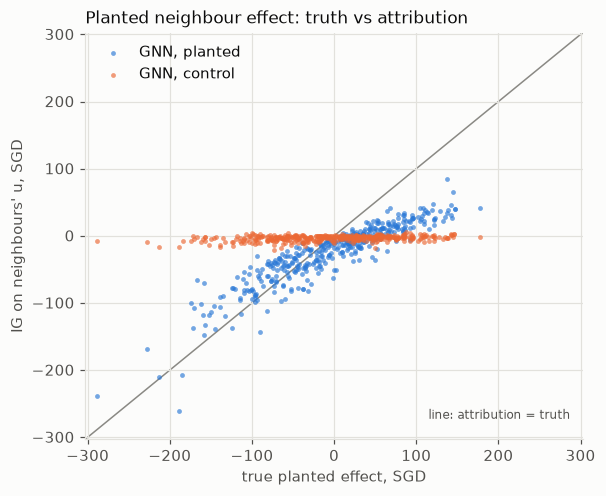

,"corr(true, IG on neighbours' u)",slope,learned/true slope,IG/learned slope,"corr(learned, IG)",per-neighbour corr,per-neighbour slope,mean |IG on neighbours' u| $,mean |IG on own u| $,mean |IG on 2-hop u| $
model,,,,,,,,,,
"GNN, planted",0.91,0.54,0.71,0.72,0.97,0.93,0.49,36.70,9.31,0.97
"GNN, control",0.35,0.02,0.01,0.70,0.85,0.48,0.02,3.78,8.45,0.17


In [14]:
def planted_attributions(name):
    model, b = models5[name]
    p, base_n, base_r = b["parts"][1], b["nodes"][FIT_BLOCKS].mean(0), b["parts"][0]["record"].mean(0)
    mu = u[FIT_BLOCKS].mean()
    per_rental, per_neighbour = [], []
    for i in rows:
        e = explainer.explain(model, b["nodes"], p["record"][i], int(p["ids"][i]), row=i,
                              node_base=base_n, record_base=base_r)
        d = b["std"] * p["scale"][i]
        hop1 = explainer.hop(e.block, e.neighbour_blocks) == 1
        # What the model actually learned: reset only the neighbours' u to the baseline, read the change.
        others = torch.from_numpy(e.neighbour_blocks)
        kept = b["nodes"][others, U].clone()
        b["nodes"][others, U] = base_n[U]
        reset = explainer.output(model, b["nodes"], p["record"][i], e.block)
        b["nodes"][others, U] = kept
        per_rental.append(dict(row=i, true=BETA * (neighbour_mean_u[e.block] - mu) * p["scale"][i],
                               learned=(e.output - reset) * d,
                               neighbours=e.neighbours[:, U].sum() * d, own=e.own[U] * d,
                               hop2=e.neighbours[~hop1, U].sum() * d))
        for j, a in zip(e.neighbour_blocks[hop1], e.neighbours[hop1, U]):
            per_neighbour.append(dict(true=BETA * (u[j] - mu) / degree[e.block] * p["scale"][i], ig=a * d))
    return pd.DataFrame(per_rental), pd.DataFrame(per_neighbour)


planted5 = {name: planted_attributions(name) for name in ["GNN, planted", "GNN, control"]}


def fit_line(x, y):
    return np.polyfit(x, y, 1)[0], np.corrcoef(x, y)[0, 1]


rows5 = []
for name, (pr, pn) in planted5.items():
    slope, corr = fit_line(pr.true, pr.neighbours)
    n_slope, n_corr = fit_line(pn.true, pn.ig)
    l_slope, l_corr = fit_line(pr.true, pr.learned)
    ig_slope, ig_corr = fit_line(pr.learned, pr.neighbours)
    rows5.append({"model": name, "corr(true, IG on neighbours' u)": corr, "slope": slope,
                  "learned/true slope": l_slope, "IG/learned slope": ig_slope, "corr(learned, IG)": ig_corr,
                  "per-neighbour corr": n_corr, "per-neighbour slope": n_slope,
                  "mean |IG on neighbours' u| $": pr.neighbours.abs().mean(),
                  "mean |IG on own u| $": pr.own.abs().mean(), "mean |IG on 2-hop u| $": pr.hop2.abs().mean()})
recovery = pd.DataFrame(rows5).set_index("model")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for (name, (pr, _)), color in zip(planted5.items(), [BLUE, ORANGE]):
    ax.scatter(pr.true, pr.neighbours, s=10, color=color, alpha=0.65, linewidths=0, label=name)
lim = np.abs(planted5["GNN, planted"][0][["true", "neighbours"]].to_numpy()).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=NEUTRAL, linewidth=1, zorder=0)
ax.text(lim * 0.95, -lim * 0.9, "line: attribution = truth", color=INK2, fontsize=8, ha="right")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("true planted effect, SGD")
ax.set_ylabel("IG on neighbours' u, SGD")
ax.set_title("Planted neighbour effect: truth vs attribution")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "planted_recovery.png", bbox_inches="tight")
plt.show()
recovery.round(2)

## 6. A GNN that learns its own edge weights

`GNN_learned_edges` weights each edge by exp(−distance / τ) × a learned function of the edge's features
(distance, age and height gaps, same subzone, same town, MRT-distance gap), with τ learned too. Its weights
summarise what it treats as a useful neighbour. Like attention, they are a diagnostic, not an explanation,
so they are set against IG below. It uses `GNN_uniform`'s epoch count (not separately tuned).

holdout RMSE 489.6 (GNN_uniform seed 0 489.8); learned tau = 0.239 km
learned feature factor (the sigmoid part, 0 to 1) by edge type:
                         size   mean    std
same_town same_subzone                     
False     False           336  0.044  0.039
          True             20  0.118  0.017
True      False          3984  0.049  0.035
          True          83592  0.134  0.061


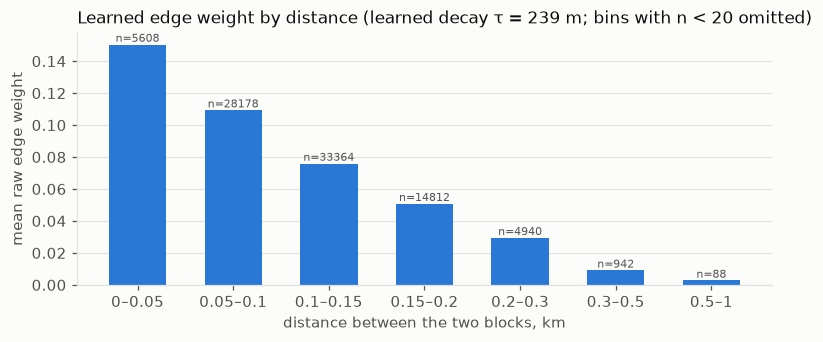

In [15]:
learned = get_model("GNN_learned_edges", 0)
with torch.no_grad():
    tau = float(torch.nn.functional.softplus(learned.log_tau).clamp(0.03, 3.0))
    raw = learned.edge_weights().numpy()
ef = graph.edge_features.numpy()
edges6 = pd.DataFrame({"km": ef[:, 0], "same_subzone": ef[:, 3] > 0.5, "same_town": ef[:, 4] > 0.5,
                       "weight": raw, "feature factor": raw / np.exp(-ef[:, 0] / tau)})
print(f"holdout RMSE {rmse(gnn.predict(learned, bundle, part), part['y']):.1f} "
      f"(GNN_uniform seed 0 {reliance.loc['GNN seed 0', 'holdout RMSE']:.1f}); learned tau = {tau:.3f} km")
print("learned feature factor (the sigmoid part, 0 to 1) by edge type:")
print(edges6.groupby(["same_town", "same_subzone"])["feature factor"].agg(["size", "mean", "std"]).round(3).to_string())

band = pd.cut(edges6.km, [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0], right=False)
by_km = edges6.groupby(band, observed=True).weight.agg(["mean", "size"])
by_km = by_km[by_km["size"] >= 20]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
x = np.arange(len(by_km))
ax.bar(x, by_km["mean"], width=0.6, color=BLUE)
for xi, (v, n) in zip(x, by_km.to_numpy()):
    ax.text(xi, v, f"n={int(n)}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(x, [f"{b.left:g}–{b.right:g}" for b in by_km.index])
ax.grid(axis="x", visible=False)
ax.set_xlabel("distance between the two blocks, km")
ax.set_ylabel("mean raw edge weight")
ax.set_title(f"Learned edge weight by distance (learned decay τ = {tau * 1000:.0f} m; bins with n < 20 omitted)")
fig.tight_layout()
fig.savefig(OUT / "learned_edge_weights.png", bbox_inches="tight")
plt.show()

In [16]:
explanations["GNN learned edges"] = explain(learned, rows)
adj = learned.adjacency().coalesce()
weight_of = dict(zip(map(tuple, adj.indices().numpy().T), adj.values().detach().numpy()))
agree, share = [], []
for e in explanations["GNN learned edges"]:
    hop1 = explainer.hop(e["block"], e["nbr_blocks"]) == 1
    nbrs = e["nbr_blocks"][hop1]
    ig = np.abs(e["nbr"][hop1].sum(1))
    w = np.array([weight_of[(e["block"], j)] for j in nbrs])
    if len(nbrs) >= 3 and np.ptp(w) > 0:
        agree.append(spearmanr(w, ig).statistic)
    share.append(np.abs(e["nbr"]).sum() / (np.abs(e["rec"]).sum() + np.abs(e["own"]).sum() + np.abs(e["nbr"]).sum()))
learned6 = {"neighbour share of |IG|": np.mean(share), "weight-vs-IG Spearman (mean)": np.nanmean(agree),
            "weight-vs-IG Spearman (median)": np.nanmedian(agree), "rentals compared": int(np.sum(~np.isnan(agree)))}
print(f"neighbour share of |IG|: {learned6['neighbour share of |IG|']:.1%} (GNN_uniform seed 0: "
      f"{reliance.loc['GNN seed 0', 'neighbour share of |IG|']:.1%})")
print(f"per-rental Spearman between a direct neighbour's learned weight and its |IG|: mean "
      f"{learned6['weight-vs-IG Spearman (mean)']:.2f}, median {learned6['weight-vs-IG Spearman (median)']:.2f} "
      f"over {learned6['rentals compared']} rentals")

neighbour share of |IG|: 32.2% (GNN_uniform seed 0: 27.1%)
per-rental Spearman between a direct neighbour's learned weight and its |IG|: mean 0.71, median 0.86 over 400 rentals


## Summary

Numbers are from this run (400 holdout rentals, 2024-01 to 2025-03); the cell below recomputes them.

- **The explanations pass every check.** The subgraph prediction matches the full graph to 2e-7; IG's
  completeness error has a median of about $1. Resetting the 5 most-attributed inputs moves a prediction
  by $293 on average, 19× more than 5 random inputs from the rental's own record and block, and about 270×
  more than 5 random inputs from anywhere in its subgraph. Rankings agree across seeds (Spearman 0.78) and
  break for an untrained network (0.24).
- **Flat attributes come first, then location.** Floor area ($147) and flat type ($115) move predictions
  most, then flat age, town/area and building height/year. LightGBM ranks the families similarly
  (Spearman 0.68), but leans much more on town/area ($154 vs $59) and less on flat age.
- **The GNN uses its neighbours but does not need them.** Neighbouring blocks carry 26–30% of the attribution,
  and deleting all edges moves predictions by $92–114 on average (out of distribution, so an upper bound). Yet
  the GNN is no more accurate than the same network without the graph (489.4–489.8 vs 488.8). The reason is
  substitution: the GNN's location effect from own block + neighbours ($198) matches the MLP's from its own
  block alone ($203), with a per-rental correlation of 0.98. Neighbours repeat the location signal the
  rental's own block already has.
- **Influence stops at direct neighbours.** A 1-hop neighbour contributes about $9; a 2-hop neighbour
  $0.4. Within the 1 km edge radius it does not fall off with distance (Spearman 0.03), but almost all edges
  are under 300 m.

- **The explainer finds a planted neighbour effect, but understates its size.** With a known effect of
  +$150 × the mean of a random block value over direct neighbours (sd $75 on holdout rents), the GNN beats the
  graph-free MLP on the planted target (489.3 vs 490.8). Two separate answers:
  - *What the model learned*: resetting only the neighbours' value moves predictions by 71% of the true
    effect.
  - *What IG reports*: IG on the neighbours' value matches that learned change in ranking (correlation 0.97;
    0.91 against the truth per rental, 0.93 per neighbour) but at about 72% of its size, and less on the
    positive side than the negative.

  The control model (same column, nothing planted) gets one tenth of the attribution ($3.80 vs $36.70), and
  2-hop neighbours get almost none ($1). So IG can be trusted for *which* neighbours and features matter and
  in which direction, and its dollar amounts are a lower bound for neighbour effects.
- **A GNN that learns its edge weights learns a 240 m neighbourhood.** Its learned decay is τ = 239 m. Edges
  inside the same subzone get about three times the weight of edges that cross a town boundary (feature
  factor 0.134 vs 0.044). Accuracy is unchanged (489.6). Its neighbours carry 32% of the attribution, and a
  direct neighbour's learned weight ranks neighbours much as IG does (per-rental Spearman: median 0.86,
  mean 0.71). Its weights are a fair summary for this model, though a diagnostic, not a proof.

**Next steps.** The neighbour-premium GNN (`scripts/gnn_neighbour_premiums.py`), where neighbours carry past
rents the block may lack, is explained in `12_interpretability_premiums.ipynb`.

In [17]:
summary = {
    "GNN seed 0 holdout RMSE": reliance.loc["GNN seed 0", "holdout RMSE"],
    "MLP holdout RMSE": reliance.loc["MLP (graph off)", "holdout RMSE"],
    "neighbour share of |IG| (seeds 0-2)": reliance.loc[["GNN seed 0", "GNN seed 1", "GNN seed 2"], "neighbour share of |IG|"].round(3).tolist(),
    "mean |Δ$| all edges removed (seed 0)": reliance.loc["GNN seed 0", "mean |Δ$| with all edges removed"],
    "GNN vs LightGBM family rank Spearman": rho,
    "fidelity ratio top/random (flat + own block) at k=5": fid.loc[5, "ratio vs flat + own block"],
    "seed stability (mean of 3 pairs)": stability.iloc[:3, 0].mean(),
    "trained vs untrained": stability.iloc[3, 0],
}
pd.Series(summary)

GNN seed 0 holdout RMSE                                          489.770414
MLP holdout RMSE                                                 488.822632
neighbour share of |IG| (seeds 0-2)                    [0.271, 0.26, 0.301]
mean |Δ$| all edges removed (seed 0)                              91.858981
GNN vs LightGBM family rank Spearman                               0.684848
fidelity ratio top/random (flat + own block) at k=5               19.143145
seed stability (mean of 3 pairs)                                   0.781167
trained vs untrained                                               0.241159
dtype: object